# Tesis paso a paso: la función de Christoffel–Darboux de cero a ModelNet10

Este cuaderno recorre **todo lo que se reporta en la tesis**, en el orden de los capítulos oficiales. Cada bloque tiene tres partes:

1. **Qué hace**: explicación corta del paso.
2. **Celdas de código**: calculan, dibujan y **verifican**. Cada verificación imprime ✔ o se detiene con ✘ si algo no cuadra.
3. **Para la tesis →**: en qué sección va, qué figura usar y un texto modelo para redactar.

Cómo usarlo: *Kernel → Restart & Run All* una vez para confirmar que todo pasa; después ejecuta celda por celda mientras escribes. Las figuras se guardan en `notebooks/figuras_tesis/` con un número y la sección a la que pertenecen.

| Parte | Capítulo oficial | Tiempo aprox. |
|---|---|---|
| A. Fundamentos y cálculo estable | 2.5 y 4.3 | segundos |
| B. Soporte y grado | 5.1 | segundos |
| C. Agrupamiento 2D | 3.3, 4.4 y 5.2 | ~1 min |
| D. Embeddings | 5.3 | ~1 min |
| E. Descriptor invariante y objetos sintéticos | 4.5 y 5.4 | segundos (o ~5 min si se recalcula) |
| F. ModelNet10 | 5.5 | segundos (lee los CSV de la corrida final) |
| G. Resumen de verificaciones y figuras | — | — |

In [1]:
%matplotlib inline
import sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (RAIZ / "src", RAIZ / "benchmarks"):
    sys.path.insert(0, str(p))
RES = RAIZ / "benchmarks" / "results"
FIG = RAIZ / "notebooks" / "figuras_tesis"
FIG.mkdir(parents=True, exist_ok=True)

# ¿Recalcular lo costoso? (False = leer los CSV ya generados por los scripts)
RECALCULAR_OBJETOS = False
MODELNET_ROOT = None   # p. ej. Path.home() / "Downloads/ModelNet10/ModelNet10" para volver a correrlo aquí

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS, ROJO, VERDE = "#363795", "#E08E0B", "#8A8A9A", "#C0392B", "#2E8B57"

VERIF, FIGS = [], []
def verifica(cond, msg):
    VERIF.append((bool(cond), msg))
    print(("✔ " if cond else "✘ ") + msg)
    assert cond, msg

def guardar(fig, nombre, seccion):
    n = len(FIGS) + 1
    archivo = FIG / f"{n:02d}_{nombre}.png"
    fig.savefig(archivo, bbox_inches="tight")
    FIGS.append((archivo.name, seccion))
    print(f"Figura guardada: {archivo.relative_to(RAIZ)}  →  {seccion}")

import pointfield
from pointfield.learning import (ChristoffelDarboux, monomial_basis, monomial_exponents, monomial_weights,
                                 CDDescriptor, moment_descriptor)
print("Repositorio:", RAIZ)

Repositorio: /tmp/pf


---
# Parte A · Fundamentos y cálculo estable (cap. 2.5 y 4.3)

## A1. La función de Christoffel a mano, en 1D

Con tres datos $X=\{-1,0,1\}$ y grado $n=2$ la base es $v(x)=(1,x,x^2)$ y todo se puede hacer a mano:

$$M=\frac1N\sum_i v(x_i)v(x_i)^\top,\qquad q(z)=v(z)^\top M^{-1}v(z),\qquad \Lambda(z)=1/q(z).$$

**Qué verificar:** (i) que $q(z)=3-4.5z^2+4.5z^4$; (ii) la identidad de traza: el promedio de $q$ sobre los datos es exactamente $s=3$; (iii) que $q$ es mínima cerca de los datos y crece fuera, es decir, $\Lambda$ es **grande donde hay datos**.

M =
 [[1.     0.     0.6667]
 [0.     0.6667 0.    ]
 [0.6667 0.     0.6667]]
✔ q(z) = 3 - 4.5 z² + 4.5 z⁴
✔ identidad de traza: promedio de q en los datos = s = 3
✔ q crece muy rápido fuera del soporte
Figura guardada: notebooks/figuras_tesis/01_ejemplo_1d.png  →  2.5.1 Definición (ejemplo)


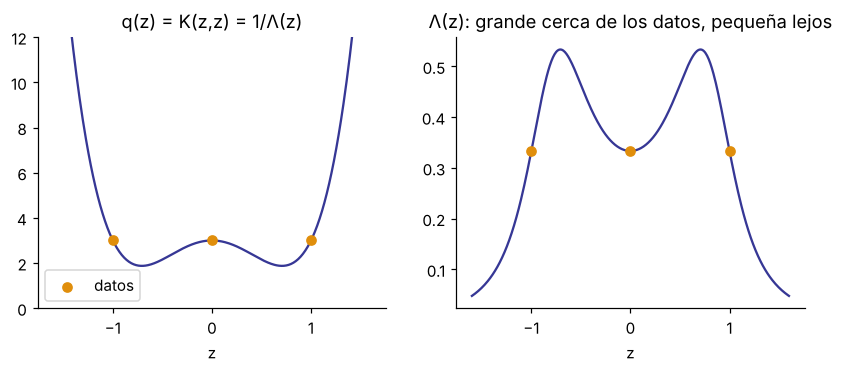

In [2]:
X1 = np.array([[-1.0], [0.0], [1.0]])
cd1 = ChristoffelDarboux(degree=2, reg=0.0).fit(X1)
print("M =\n", np.round(cd1.moment_matrix_, 4))

z = np.linspace(-1.6, 1.6, 400)[:, None]
q = cd1.score(z)
q_formula = 3 - 4.5 * z[:, 0] ** 2 + 4.5 * z[:, 0] ** 4
verifica(np.allclose(q, q_formula, atol=1e-9), "q(z) = 3 - 4.5 z² + 4.5 z⁴")
verifica(np.isclose(cd1.score(X1).mean(), cd1.basis_size_), f"identidad de traza: promedio de q en los datos = s = {cd1.basis_size_}")
verifica(cd1.score(np.array([[3.0]]))[0] > 100 * cd1.score(X1).max(), "q crece muy rápido fuera del soporte")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(z, q, color=AZUL); ax[0].scatter(X1[:, 0], cd1.score(X1), color=NARANJA, zorder=3, label="datos")
ax[0].set_title("q(z) = K(z,z) = 1/Λ(z)"); ax[0].set_ylim(0, 12); ax[0].legend()
ax[1].plot(z, 1 / q, color=AZUL); ax[1].scatter(X1[:, 0], 1 / cd1.score(X1), color=NARANJA, zorder=3)
ax[1].set_title("Λ(z): grande cerca de los datos, pequeña lejos")
for a in ax: a.set_xlabel("z")
guardar(fig, "ejemplo_1d", "2.5.1 Definición (ejemplo)")
plt.show()

> **Para la tesis → 2.5.1 Definición matemática (ejemplo) o Anexo B**
>
> *Figura:* `01_ejemplo_1d.png` — «Función de Christoffel para X = {−1, 0, 1} con n = 2. Λ es máxima en los datos y decae fuera de su soporte.»
>
> *Texto modelo:* Para X = {−1, 0, 1} y n = 2, la matriz de momentos es invertible y se obtiene q(z) = 3 − 4.5z² + 4.5z⁴. En cada dato q vale 3, que es el número de monomios s; esto ilustra la identidad de traza, según la cual el promedio de q sobre los datos es igual a s. Fuera del intervalo [−1, 1], q crece como z⁴ y Λ = 1/q tiende a cero.
>
> *Notas:* Este ejemplo es el mejor lugar para corregir el error de §3.5.1: Λ es grande donde hay datos.

## A2. Grado 1 = distancia de Mahalanobis

Con $n=1$, $q(x)=1+(x-\mu)^\top\Sigma^{-1}(x-\mu)$. Sirve para explicar el grado 1 y, más adelante, la afinidad local (M1).

In [3]:
rng = np.random.default_rng(2)
X = rng.normal(size=(500, 2)) @ np.array([[2.0, 0.3], [0.0, 0.5]])
cdm = ChristoffelDarboux(1, reg=1e-12).fit(X)
mu, S = X.mean(0), np.cov(X.T, bias=True)
d = X - mu
maha = np.einsum("ij,jk,ik->i", d, np.linalg.inv(S), d)
verifica(np.allclose(cdm.score(X), 1 + maha, rtol=1e-6), "grado 1: q(x) = 1 + Mahalanobis²(x)")

✔ grado 1: q(x) = 1 + Mahalanobis²(x)


> **Para la tesis → 2.5.2 Kernel y matriz de momentos (una frase) y 4.4 (afinidad local)**
>
> *Texto modelo:* Con grado 1, q(x) = 1 + (x − μ)ᵀΣ⁻¹(x − μ): la función de Christoffel generaliza la distancia de Mahalanobis a grados mayores.

## A3. Formulación variacional

$\Lambda(z)=\min\{a^\top A a : a^\top v(z)=1\}$ con $A=M+\varepsilon I$. El mínimo se alcanza en $a^*=A^{-1}v/(v^\top A^{-1}v)$.
**Qué verificar:** que el valor en $a^*$ es $1/q(z)$ y que cualquier otro polinomio que vale 1 en $z$ tiene más energía.

In [4]:
X = rng.normal(size=(300, 2))
cdv = ChristoffelDarboux(2, reg=1e-6).fit(X)
A = cdv.moment_matrix_ + cdv.eps_ * np.eye(cdv.basis_size_)
zz = np.array([[0.8, -1.5]])
v = cdv.design(zz)[0]
a_opt = np.linalg.solve(A, v); a_opt /= v @ a_opt
verifica(np.isclose(a_opt @ A @ a_opt, 1 / cdv.score(zz)[0]), "a*ᵀ A a* = Λ(z)")
P = np.eye(len(v)) - np.outer(v, v) / (v @ v)          # direcciones que mantienen aᵀv = 1
otros = [a_opt + P @ rng.normal(size=len(v)) for _ in range(1000)]
verifica(min(a @ A @ a for a in otros) >= a_opt @ A @ a_opt - 1e-12, "ningún otro polinomio con p(z)=1 tiene menos energía")

✔ a*ᵀ A a* = Λ(z)
✔ ningún otro polinomio con p(z)=1 tiene menos energía


> **Para la tesis → 2.5.3 Formulación variacional**
>
> *Texto modelo:* Λ_n(z) es la menor energía promedio, sobre los datos, de un polinomio de grado n que vale 1 en z. Si z está rodeado de datos, cualquier polinomio así tiene energía grande; si z está lejos, puede valer 1 en z y casi cero en los datos.

## A4. Singularidad: por qué ridge y no pseudoinversa

En la circunferencia unitaria con $n=2$, el polinomio $x^2+y^2-1$ vale cero en todos los datos, así que $M$ es singular (rango 5 de 6).
**Qué verificar:** el rango; que la pseudoinversa da al centro un $q$ **menor** que el de los datos (lo trata como típico) y que con $A=M+\varepsilon I$ el centro queda claramente fuera.

rango(M) = 5 de 6;  q(centro): pinv = 0.452, ridge = 67.1;  q medio en datos = 4.94
✔ M es singular: rango 5 de 6
✔ pinv: el centro parece MÁS típico que cualquier dato (incorrecto)
✔ ridge: el centro queda fuera del soporte


Figura guardada: notebooks/figuras_tesis/02_circulo_pinv_vs_ridge.png  →  2.5.4 Singularidad y regularización


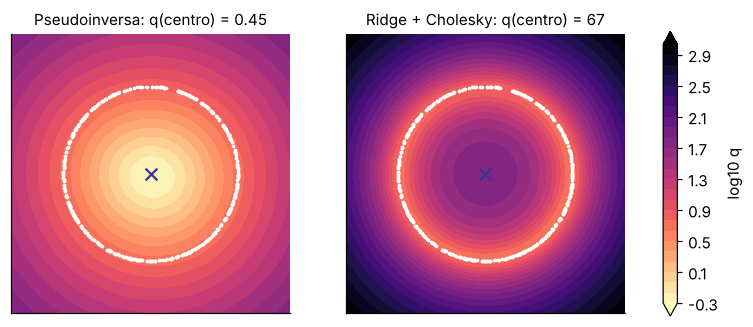

In [5]:
from pointfield.geometry.shapes2d import Circle
Xc = Circle(1.0).sample(400, seed=0)
cdc = ChristoffelDarboux(2, reg=0.01, basis="weighted").fit(Xc)
rango = np.linalg.matrix_rank(cdc.moment_matrix_, tol=1e-10)
o = np.zeros((1, 2)); vo = cdc.design(o)
q_ridge = cdc.score(o)[0]
q_pinv = (vo @ np.linalg.pinv(cdc.moment_matrix_) @ vo.T)[0, 0]
print(f"rango(M) = {rango} de {cdc.basis_size_};  q(centro): pinv = {q_pinv:.3f}, ridge = {q_ridge:.1f};  q medio en datos = {cdc.score(Xc).mean():.2f}")
verifica(rango == 5, "M es singular: rango 5 de 6")
verifica(q_pinv < cdc.score(Xc).min(), "pinv: el centro parece MÁS típico que cualquier dato (incorrecto)")
verifica(q_ridge > 50, "ridge: el centro queda fuera del soporte")

g = np.linspace(-1.6, 1.6, 220); GX, GY = np.meshgrid(g, g); G = np.column_stack([GX.ravel(), GY.ravel()])
VG = cdc.design(G)
Q_pinv = np.einsum("ij,jk,ik->i", VG, np.linalg.pinv(cdc.moment_matrix_), VG).reshape(GX.shape)
Q_ridge = cdc.score(G).reshape(GX.shape)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
niveles = np.linspace(np.log10(max(Q_pinv.min(), 1e-3)), np.log10(Q_ridge.max()), 26)   # misma escala de color en ambos paneles
for a, Q, t in ((ax[0], Q_pinv, f"Pseudoinversa: q(centro) = {q_pinv:.2f}"), (ax[1], Q_ridge, f"Ridge + Cholesky: q(centro) = {q_ridge:.0f}")):
    im = a.contourf(GX, GY, np.log10(np.maximum(Q, 1e-3)), levels=niveles, cmap="magma_r", extend="both")
    a.scatter(Xc[:, 0], Xc[:, 1], s=2, c="white"); a.scatter([0], [0], marker="x", c=AZUL, s=60)
    a.set_aspect("equal"); a.set_title(t, fontsize=10); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=ax, shrink=0.8, label="log10 q", format="%.1f")
guardar(fig, "circulo_pinv_vs_ridge", "2.5.4 Singularidad y regularización")
plt.show()

> **Para la tesis → 2.5.4 Singularidad y regularización (y 4.3)**
>
> *Figura:* `02_circulo_pinv_vs_ridge.png` — «Circunferencia unitaria con n = 2. Izquierda: con pseudoinversa el centro obtiene q menor que los datos. Derecha: con A = M + εI el centro queda fuera del soporte.»
>
> *Texto modelo:* Cuando los datos satisfacen una ecuación polinomial de grado ≤ n, la matriz de momentos es singular. En la circunferencia unitaria con n = 2, x² + y² − 1 se anula en todos los datos y M tiene rango 5 de 6. La pseudoinversa ignora justamente esa dirección y asigna al centro un valor de q menor que el de cualquier dato. Con A = M + εI, ε = 0.01·tr(M)/s, el centro obtiene q ≈ 67 y queda correctamente fuera del soporte.

## A5. Cholesky en lugar de invertir

$q(z)=\|L^{-1}v(z)\|^2$ con $A=LL^\top$: una sustitución triangular, sin formar $A^{-1}$. **Qué verificar:** que coincide con la inversa explícita.

In [6]:
X = rng.normal(size=(300, 3))
cdk = ChristoffelDarboux(2, reg=1e-6, basis="weighted").fit(X)
V = cdk.design(X[:50]); A = cdk.moment_matrix_ + cdk.eps_ * np.eye(cdk.basis_size_)
ref = np.einsum("ij,jk,ik->i", V, np.linalg.inv(A), V)
err = np.max(np.abs(cdk.score(X[:50]) - ref) / ref)
verifica(err < 1e-8, f"Cholesky = inversa explícita (error relativo máx. {err:.1e})")
print(f"Número de condición de M: {cdk.condition_number_:.2e}")

✔ Cholesky = inversa explícita (error relativo máx. 1.3e-15)
Número de condición de M: 1.53e+01


> **Para la tesis → 4.3 Cálculo estable de la función CD**
>
> *Texto modelo:* El valor q(z) se calcula como ‖L⁻¹v(z)‖², donde A = LLᵀ es la factorización de Cholesky de la matriz regularizada; así se evita formar A⁻¹. En la implementación, el resultado coincide con la inversa explícita con error relativo menor a 10⁻⁸.

## A6. Base ponderada: invariancia a rotaciones

Con monomios simples, rotar los datos cambia los valores propios de $M$. Con la escala $\sqrt{k!/\alpha!}$ se cumple $\langle\phi_k(x),\phi_k(y)\rangle=(x^\top y)^k$ y el espectro **no cambia**.

In [7]:
from pointfield.core.pose import random_rotation
x, y = rng.normal(size=(2, 3))
for k in (1, 2, 3):
    t = [e for e in monomial_exponents(3, k) if len(e) == k]
    w = monomial_weights(t)
    verifica(np.isclose(monomial_basis(x[None], t, w)[0] @ monomial_basis(y[None], t, w)[0], (x @ y) ** k), f"bloque de grado {k}: ⟨φ(x), φ(y)⟩ = (xᵀy)^{k}")

X = rng.normal(size=(400, 3)) * [2.0, 1.0, 0.4]
R = random_rotation(3, seed=5)
def espectro(X, base):
    return np.linalg.eigvalsh(ChristoffelDarboux(2, reg=1e-8, basis=base).fit(X).moment_matrix_)
dif_w = np.max(np.abs(espectro(X, "weighted") - espectro(X @ R.T, "weighted")))
dif_m = np.max(np.abs(espectro(X, "monomial") - espectro(X @ R.T, "monomial")))
print(f"cambio del espectro al rotar: base ponderada {dif_w:.1e}, monomios simples {dif_m:.1e}")
verifica(dif_w < 1e-10 and dif_m > 1e-3, "sólo la base ponderada da un espectro invariante a rotaciones")

✔ bloque de grado 1: ⟨φ(x), φ(y)⟩ = (xᵀy)^1
✔ bloque de grado 2: ⟨φ(x), φ(y)⟩ = (xᵀy)^2
✔ bloque de grado 3: ⟨φ(x), φ(y)⟩ = (xᵀy)^3
cambio del espectro al rotar: base ponderada 5.7e-14, monomios simples 1.4e+01
✔ sólo la base ponderada da un espectro invariante a rotaciones


> **Para la tesis → 4.3 (base ponderada) y 4.5 (descriptor invariante)**
>
> *Texto modelo:* Para que el descriptor no dependa de la orientación, cada monomio x^α de grado k se escala por √(k!/α!). Con esta escala, el producto interno de dos bloques de grado k es (xᵀy)^k, por lo que rotar la nube sólo rota la base y los valores propios de M no cambian. Con monomios sin escalar el espectro sí cambia al rotar.

---
# Parte B · Estimación de soporte y efecto del grado (cap. 5.1)

Corona 2D (radios 0.75–1, N = 300, semilla 0) normalizada. Se dibuja el conjunto de nivel de $q$ en el percentil 97 de los datos, con grados 1, 2, 4 y 6. Es exactamente lo que hace `benchmarks/fig_cd_2d.py`.

**Qué verificar:** que con grado 1 el hueco queda **dentro** del soporte y desde grado 2 queda **fuera**; que el número de condición crece muy rápido; que las cifras coinciden con `cd_2d_degree_diagnostics.csv`.

✔ grado 1: razón del hueco = 0.334 (igual al CSV)
✔ grado 2: razón del hueco = 7.76 (igual al CSV)


✔ grado 4: razón del hueco = 158 (igual al CSV)
✔ grado 6: razón del hueco = 4.6e+03 (igual al CSV)


✔ el hueco sale del soporte a partir de n = 2


Figura guardada: notebooks/figuras_tesis/03_soporte_grado.png  →  5.1 Estimación de soporte y efecto del grado


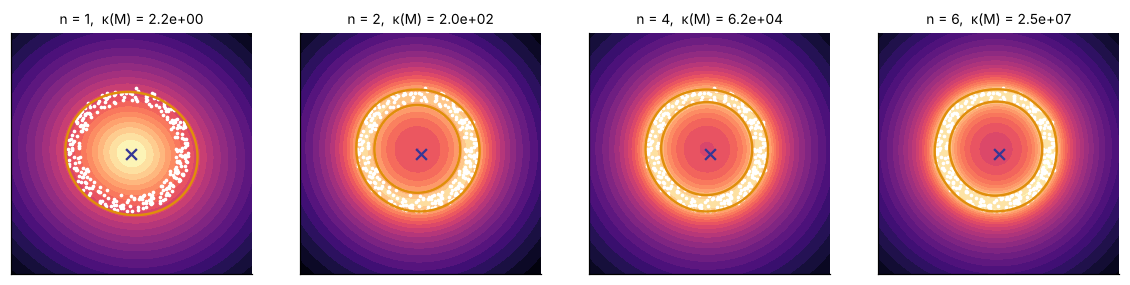

,s,N/s,κ(M),q(hueco)/mediana,hueco fuera
grado,,,,,
1,3,100.0,2.2e+00,0.334,False
2,6,50.0,2.0e+02,7.76,True
4,15,20.0,6.2e+04,158,True
6,28,10.7,2.5e+07,4.6e+03,True


In [8]:
from pointfield.core.dataset import PointDataset
from pointfield.geometry.shapes2d import Annulus
Xa = PointDataset(Annulus(0.75, 1.0).sample(300, seed=0), np.zeros(300, int)).normalized().X
hueco = np.array([[0.0, 0.0]])
csv = pd.read_csv(RES / "cd_2d_degree_diagnostics.csv")
csv = csv[csv.dataset.str.startswith("anillo")].set_index("degree")

g = np.linspace(-2.2, 2.2, 240); GX, GY = np.meshgrid(g, g); G = np.column_stack([GX.ravel(), GY.ravel()])
fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
filas = []
for a, n in zip(ax, (1, 2, 4, 6)):
    cd = ChristoffelDarboux(n, reg=1e-8).fit(Xa)
    qd = cd.score(Xa); nivel = np.percentile(qd, 97)
    razon = cd.score(hueco)[0] / np.median(qd)
    filas.append({"grado": n, "s": cd.basis_size_, "N/s": len(Xa) / cd.basis_size_, "κ(M)": cd.condition_number_,
                  "q(hueco)/mediana": razon, "hueco fuera": bool(cd.score(hueco)[0] > nivel)})
    verifica(np.isclose(razon, csv.loc[n, "ratio_hueco"], rtol=1e-6), f"grado {n}: razón del hueco = {razon:.3g} (igual al CSV)")
    Q = cd.score(G).reshape(GX.shape)
    a.contourf(GX, GY, np.log10(Q), levels=24, cmap="magma_r")
    a.contour(GX, GY, Q, levels=[nivel], colors=[NARANJA], linewidths=1.6)
    a.scatter(Xa[:, 0], Xa[:, 1], s=2, c="white"); a.scatter([0], [0], marker="x", c=AZUL, s=50)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"n = {n},  κ(M) = {cd.condition_number_:.1e}", fontsize=9)
tabla_grado = pd.DataFrame(filas).set_index("grado")
verifica(not tabla_grado.loc[1, "hueco fuera"] and tabla_grado.loc[2, "hueco fuera"], "el hueco sale del soporte a partir de n = 2")
guardar(fig, "soporte_grado", "5.1 Estimación de soporte y efecto del grado")
plt.show()
display(tabla_grado.style.format({"N/s": "{:.1f}", "κ(M)": "{:.1e}", "q(hueco)/mediana": "{:.3g}"}))

> **Para la tesis → 5.1 Estimación de soporte y efecto del grado**
>
> *Figura:* `03_soporte_grado.png` — «Conjunto de nivel de q (percentil 97 de los datos, en naranja) para una corona con grados 1, 2, 4 y 6. La cruz marca el centro del hueco.»
>
> *Texto modelo:* Con grado 1 el hueco central queda dentro del soporte estimado: q en el centro es sólo 0.33 veces la mediana sobre los datos. Desde el grado 2 queda fuera (7.8 veces la mediana) y con grado 4 la separación llega a 158 veces. A cambio, el número de condición de M pasa de 2.2 con n = 1 a 2.5 × 10⁷ con n = 6, lo que justifica la regularización y el uso de grados bajos en el resto del trabajo.
>
> *Notas:* La tabla de arriba es la tabla de §5.1; las cifras salen de cd_2d_degree_diagnostics.csv.

---
# Parte C · Agrupamiento 2D (cap. 3.3, 4.4 y 5.2)

## C1. Los escenarios y sus perturbaciones

Cuatro escenarios de desarrollo y dos reservados (sólo para evaluar), con referencia conocida. Las perturbaciones se aplican con la semilla del caso + 1000, igual que en `benchmarks/common.py`.

Figura guardada: notebooks/figuras_tesis/04_escenarios_2d.png  →  3.3 Datos (escenarios 2D)


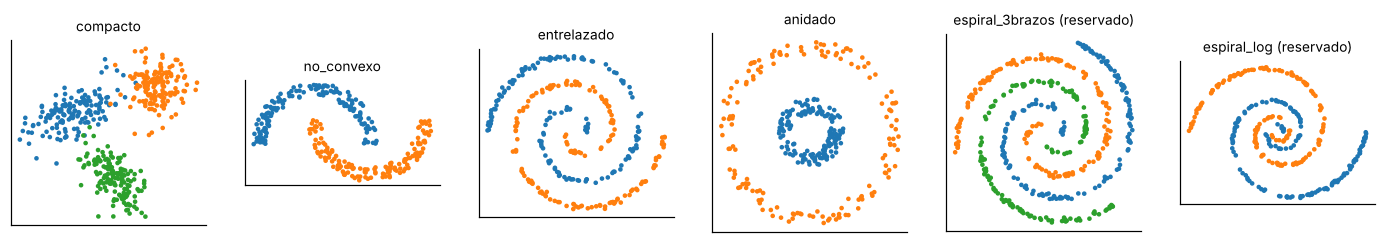

Figura guardada: notebooks/figuras_tesis/05_perturbaciones_2d.png  →  3.3 Datos (perturbaciones)


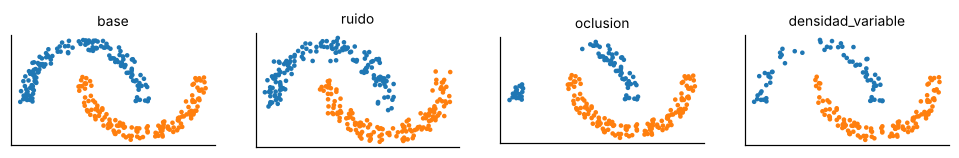

In [9]:
from common import load_case, METHODS, MAIN_CASES, HELD_OUT_CASES, VARIANTS
CASOS = MAIN_CASES + HELD_OUT_CASES
fig, ax = plt.subplots(1, 6, figsize=(16, 2.9))
for a, caso in zip(ax, CASOS):
    ds = load_case(caso, "base", 100)
    a.scatter(ds.X[:, 0], ds.X[:, 1], c=ds.y, cmap="tab10", s=4, vmin=0, vmax=9)
    a.set_title(caso + (" (reservado)" if caso in HELD_OUT_CASES else ""), fontsize=9)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
guardar(fig, "escenarios_2d", "3.3 Datos (escenarios 2D)")
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(11, 2.9))
for a, var in zip(ax, VARIANTS):
    ds = load_case("no_convexo", var, 100)
    a.scatter(ds.X[:, 0], ds.X[:, 1], c=ds.y, cmap="tab10", s=4, vmin=0, vmax=9)
    a.set_title(var, fontsize=9); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
guardar(fig, "perturbaciones_2d", "3.3 Datos (perturbaciones)")
plt.show()

> **Para la tesis → 3.3 Datos**
>
> *Figura:* `04_escenarios_2d.png` y `05_perturbaciones_2d.png`.
>
> *Texto modelo:* Se usaron seis escenarios 2D con referencia conocida: compacto (tres gaussianas), no convexo (dos lunas), entrelazado (dos espirales), anidado (dos anillos) y dos escenarios reservados (espiral de tres brazos y espiral logarítmica) que no intervinieron en ningún ajuste. Cada escenario se evaluó limpio y con ruido gaussiano, oclusión de una franja y densidad variable.

## C2. Correr los siete métodos (semilla 100, sin perturbar) y comparar con el CSV

Se ejecutan exactamente las fábricas de `benchmarks/common.py`. **Qué verificar:** que el ARI de cada método y caso coincide con `clustering_2d_eval.csv` para esa semilla.

✔ los 42 ARI recalculados coinciden con el CSV (diferencia máx. 1.1e-16)


Figura guardada: notebooks/figuras_tesis/06_agrupamiento_2d_semilla100.png  →  5.2 Agrupamiento 2D (figura principal)


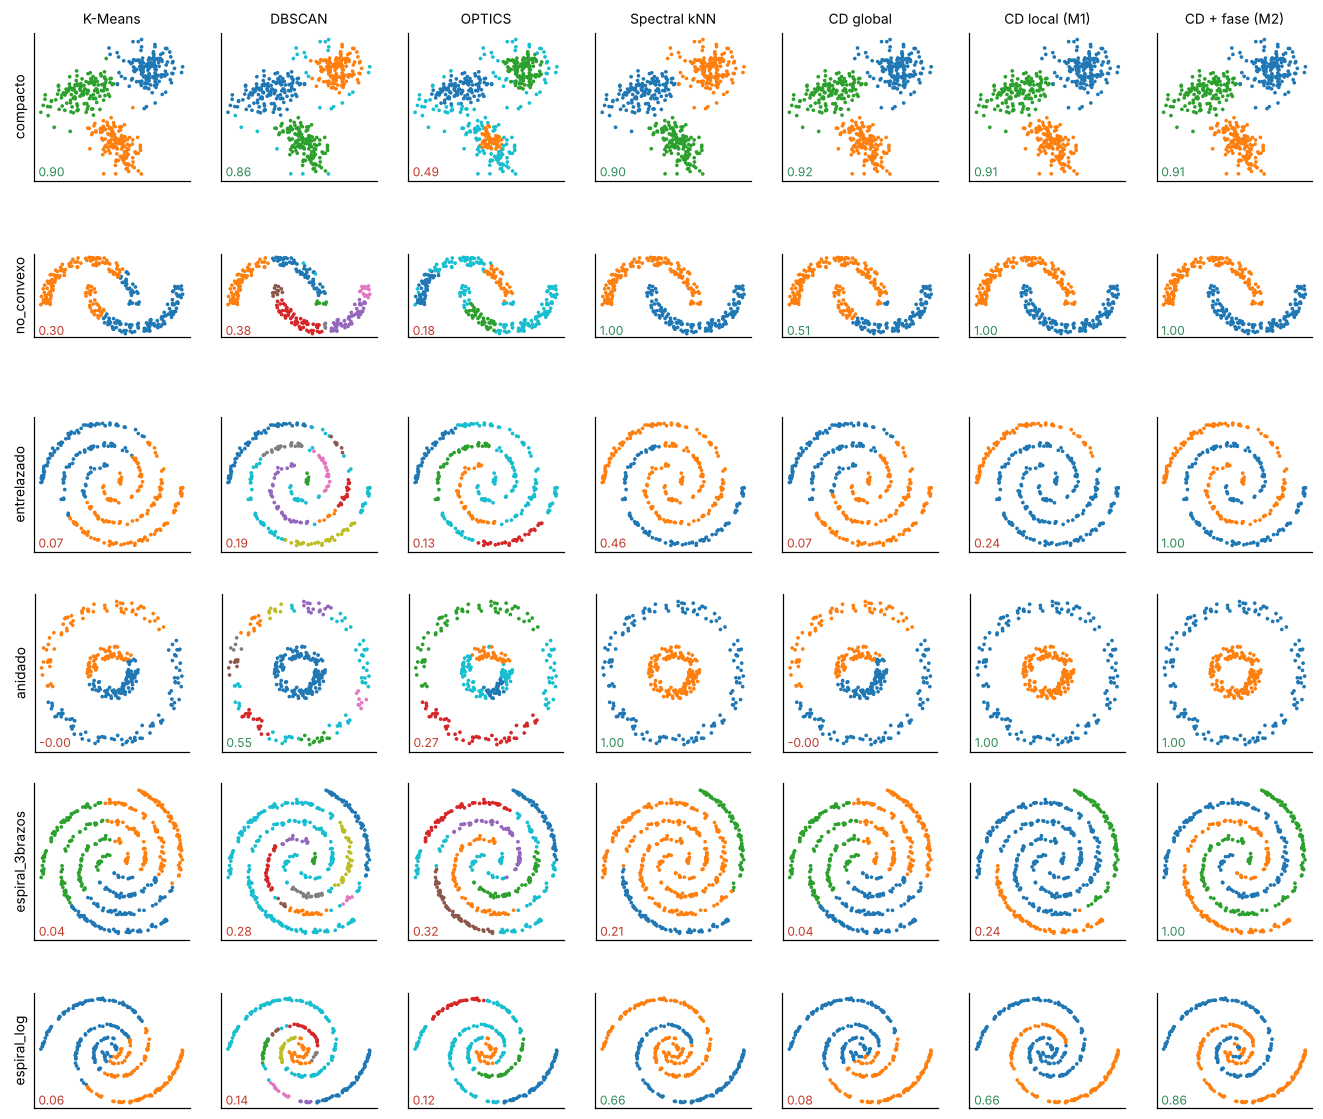

In [10]:
from sklearn.metrics import adjusted_rand_score
ev = pd.read_csv(RES / "clustering_2d_eval.csv")
ev100 = ev[(ev.seed == 100) & (ev.variant == "base")].set_index(["case", "method"]).ARI
CORTO = {"CD global (inicial)": "CD global", "CD local-espectral (mejora 1)": "CD local (M1)",
         "CD + fase Szegő (mejora 2)": "CD + fase (M2)", "Spectral (kNN)": "Spectral kNN"}
etiquetas, ari = {}, {}
for caso in CASOS:
    ds = load_case(caso, "base", 100)
    for m, (fab, *_ ) in METHODS.items():
        lab = np.asarray(fab(ds.n_groups).fit_predict(ds.X))
        etiquetas[caso, m] = lab
        ari[caso, m] = adjusted_rand_score(ds.y, lab)
dif = max(abs(ari[k] - ev100[k]) for k in ari)
verifica(dif < 1e-9, f"los 42 ARI recalculados coinciden con el CSV (diferencia máx. {dif:.1e})")

fig, ax = plt.subplots(len(CASOS), len(METHODS), figsize=(15, 13))
for i, caso in enumerate(CASOS):
    X = load_case(caso, "base", 100).X
    for j, m in enumerate(METHODS):
        a = ax[i, j]; lab = etiquetas[caso, m]
        a.scatter(X[:, 0], X[:, 1], c=np.where(lab < 0, 9, lab), cmap="tab10", s=2, vmin=0, vmax=9)
        a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
        a.text(0.03, 0.03, f"{ari[caso, m]:.2f}", transform=a.transAxes, fontsize=8, color=ROJO if ari[caso, m] < 0.5 else VERDE)
        if i == 0: a.set_title(CORTO.get(m, m), fontsize=9)
        if j == 0: a.set_ylabel(caso, fontsize=9)
guardar(fig, "agrupamiento_2d_semilla100", "5.2 Agrupamiento 2D (figura principal)")
plt.show()

> **Para la tesis → 5.2 Agrupamiento de puntos en 2D**
>
> *Figura:* `06_agrupamiento_2d_semilla100.png` — «Agrupamientos de los siete métodos en los seis escenarios (semilla 100). El número es el ARI.» Alternativa ya existente: `benchmarks/figures/fig_heatmap_ari.png`.
>
> *Notas:* La figura muestra una semilla; la tabla de C3 promedia las cinco. Decirlo en el pie.

## C3. Tablas de la tesis (promedio de las semillas 100–104) y compuerta de fase

In [11]:
res = pd.read_csv(RES / "tabla_clustering_resumen.csv")
orden = list(METHODS)
for var in VARIANTS:
    t = res[res.variant == var].pivot_table(index="case", columns="method", values="ARI_mean").reindex(index=CASOS, columns=orden).rename(columns=CORTO)
    display(Markdown(f"**ARI medio · variante `{var}`**")); display(t.round(2))
    if var == "base": base = t
verifica(base.loc["entrelazado", "CD + fase (M2)"] > 0.99 and base.loc["espiral_3brazos", "CD + fase (M2)"] > 0.99, "M2 resuelve las espirales limpias, también la reservada")
verifica(abs(base.loc["no_convexo", "CD local (M1)"] - base.loc["no_convexo", "Spectral kNN"]) < 0.01, "M1 iguala a Spectral kNN en lunas")
verifica(base.loc["no_convexo", "CD global"] < 0.4, "CD global falla en formas no convexas (se comporta como K-Means)")
comp = pd.read_csv(RES / "tabla_compuerta_szego.csv").pivot_table(index="case", columns="variant", values="fase_activada").reindex(index=CASOS, columns=VARIANTS)
display(Markdown("**Fracción de semillas con la fase activada**")); display(comp.round(2))
verifica((comp["oclusion"].fillna(0) == 0).all() and (comp["densidad_variable"].fillna(0) == 0).all(), "la compuerta se apaga con oclusión y densidad variable en todos los casos")

**ARI medio · variante `base`**

method,K-Means,DBSCAN,OPTICS,Spectral kNN,CD global,CD local (M1),CD + fase (M2)
case,,,,,,,
compacto,0.93,0.79,0.61,0.95,0.96,0.95,0.95
no_convexo,0.27,0.44,0.26,1.00,0.33,1.00,1.00
entrelazado,0.06,0.16,0.22,0.21,0.06,0.17,1.00
anidado,0.00,0.56,0.24,1.00,0.00,1.00,1.00
espiral_3brazos,0.03,0.24,0.40,0.20,0.03,0.40,1.00
espiral_log,0.05,0.11,0.15,0.52,0.06,0.55,0.92


**ARI medio · variante `ruido`**

method,K-Means,DBSCAN,OPTICS,Spectral kNN,CD global,CD local (M1),CD + fase (M2)
case,,,,,,,
compacto,0.92,0.57,0.53,0.94,0.95,0.94,0.94
no_convexo,0.27,0.71,0.28,0.98,0.27,1.00,0.94
entrelazado,0.05,0.13,0.11,0.04,0.05,0.05,0.42
anidado,0.00,0.56,0.28,1.00,0.01,1.00,1.00
espiral_3brazos,0.03,0.14,0.05,0.06,0.03,0.07,0.07
espiral_log,0.05,0.18,0.16,0.28,0.05,0.34,0.62


**ARI medio · variante `oclusion`**

method,K-Means,DBSCAN,OPTICS,Spectral kNN,CD global,CD local (M1),CD + fase (M2)
case,,,,,,,
compacto,0.90,0.83,0.59,0.91,0.93,0.88,0.88
no_convexo,0.15,0.51,0.17,0.56,0.16,0.66,0.66
entrelazado,0.05,0.21,0.16,0.19,0.04,0.16,0.16
anidado,0.01,0.76,0.20,1.00,0.01,1.00,1.00
espiral_3brazos,0.02,0.27,0.31,0.19,0.02,0.26,0.26
espiral_log,0.04,0.14,0.13,0.28,0.04,0.24,0.24


... (2 outputs left out)

✔ M2 resuelve las espirales limpias, también la reservada
✔ M1 iguala a Spectral kNN en lunas
✔ CD global falla en formas no convexas (se comporta como K-Means)


**Fracción de semillas con la fase activada**

variant,base,ruido,oclusion,densidad_variable
case,,,,
compacto,0.0,0.0,0.0,0.0
no_convexo,1.0,0.8,0.0,0.0
entrelazado,1.0,0.4,0.0,0.0
anidado,0.0,0.0,0.0,0.0
espiral_3brazos,1.0,0.0,0.0,0.0
espiral_log,1.0,1.0,0.0,0.0


✔ la compuerta se apaga con oclusión y densidad variable en todos los casos


> **Para la tesis → 5.2 (tablas) y 5.7 (H2)**
>
> *Texto modelo:* El agrupamiento CD global se comporta como K-Means: alcanza 0.96 en el escenario compacto y falla en formas no convexas. La afinidad local CD (M1) iguala a Spectral kNN y resuelve lunas y anillos. La fase angular con compuerta (M2) resuelve todas las espirales limpias, incluidas las reservadas. Con oclusión o densidad variable la compuerta no se activa y M2 regresa al resultado de M1, por lo que H2 se confirma sólo en datos limpios.

---
# Parte D · Embeddings (cap. 5.3)

Escenarios enrollados en 3D (rollo suizo) y proyectados de vuelta a 2D; se conoce la coordenada original, así que se puede medir *trustworthiness* (T), *continuity* (C) y exactitud 5-NN. Se recalcula un caso y se compara con `embeddings_2d_eval.csv`.

✔ PCA: T = 0.755 (igual al CSV)
✔ Kernel PCA (RBF): T = 0.742 (igual al CSV)
✔ Isomap: T = 0.766 (igual al CSV)
✔ Laplacian Eigenmaps: T = 0.788 (igual al CSV)


✔ UMAP: T = 0.937 (igual al CSV)
✔ CD local-espectral: T = 0.801 (igual al CSV)
Figura guardada: notebooks/figuras_tesis/07_embeddings_entrelazado.png  →  5.3 Embeddings


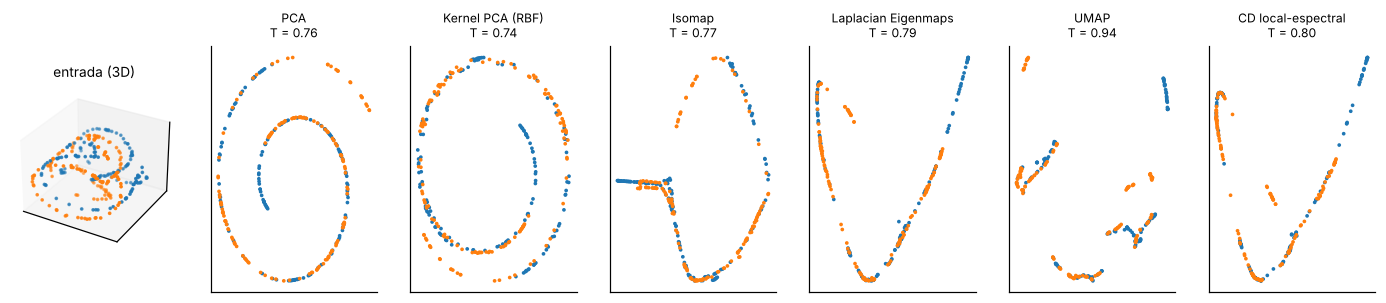

,T,C,kNN_acc
method,,,
PCA,0.81,0.96,0.80
Kernel PCA (RBF),0.80,0.95,0.80
Isomap,0.86,0.96,0.88
Laplacian Eigenmaps,0.86,0.95,0.83
UMAP,0.95,0.96,0.92
CD local-espectral,0.86,0.95,0.83


✔ UMAP es el mejor en trustworthiness
✔ el embedding CD local empata con Laplacian Eigenmaps


In [12]:
from sklearn.manifold import trustworthiness
import benchmark_embeddings_2d as BE
X3, Z, y = BE.rolled_case("entrelazado", 100)
emb = pd.read_csv(RES / "embeddings_2d_eval.csv")
fila = emb[(emb.case == "entrelazado") & (emb.seed == 100)].set_index("method")
fig = plt.figure(figsize=(16, 2.9))
a = fig.add_subplot(1, 7, 1, projection="3d"); a.scatter(*X3.T, c=y, cmap="tab10", s=2, vmin=0, vmax=9)
a.set_title("entrada (3D)", fontsize=9); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
for j, m in enumerate(BE.EMBEDDERS):
    E = BE.embed(m, X3)
    T = trustworthiness(Z, E, n_neighbors=BE.K)
    verifica(abs(T - fila.loc[m, "T"]) < 1e-6, f"{m}: T = {T:.3f} (igual al CSV)")
    a = fig.add_subplot(1, 7, j + 2); a.scatter(E[:, 0], E[:, 1], c=y, cmap="tab10", s=2, vmin=0, vmax=9)
    a.set_title(f"{m}\nT = {T:.2f}", fontsize=8); a.set_xticks([]); a.set_yticks([])
guardar(fig, "embeddings_entrelazado", "5.3 Embeddings")
plt.show()
tabla_emb = emb.groupby("method")[["T", "C", "kNN_acc"]].mean().reindex(list(BE.EMBEDDERS))
display(tabla_emb.round(2))
verifica(tabla_emb["T"].idxmax() == "UMAP", "UMAP es el mejor en trustworthiness")
verifica(abs(tabla_emb.loc["CD local-espectral", "T"] - tabla_emb.loc["Laplacian Eigenmaps", "T"]) < 0.01, "el embedding CD local empata con Laplacian Eigenmaps")

> **Para la tesis → 5.3 Embeddings**
>
> *Figura:* `07_embeddings_entrelazado.png` (un caso) o `benchmarks/figures/fig_grid_embeddings.png`.
>
> *Texto modelo:* El embedding CD local queda al nivel de Laplacian Eigenmaps (trustworthiness 0.86), lo esperable porque ambos son embeddings espectrales de un grafo de vecindad; UMAP preserva mejor la estructura local (0.95).
>
> *Notas:* UMAP puede variar ligeramente entre versiones de la biblioteca; si su verificación falla por milésimas, anota la versión usada.

---
# Parte E · Descriptor invariante y objetos sintéticos (cap. 4.5 y 5.4)

## E1. Las familias de objetos

Figura guardada: notebooks/figuras_tesis/08_familias_3d.png  →  3.3 Datos (objetos sintéticos)


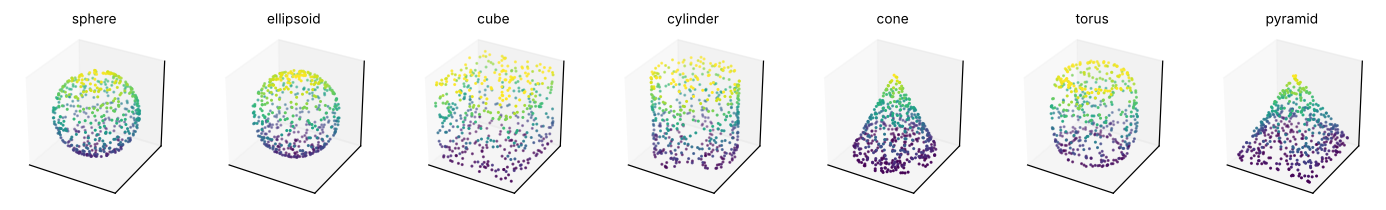

In [13]:
from pointfield.objects import make_object_dataset, random_similarity, FAMILIES_3D
nubes, etq, fams = make_object_dataset(3, 1, 512, seed=0, transform=False)   # 512 puntos, como en los experimentos
fig = plt.figure(figsize=(16, 2.6))
for j, (Xo, f) in enumerate(zip(nubes, fams)):
    a = fig.add_subplot(1, len(fams), j + 1, projection="3d")
    a.scatter(*Xo.T, s=1, c=Xo[:, 2], cmap="viridis"); a.set_title(f, fontsize=9)
    a.set_xticks([]); a.set_yticks([]); a.set_zticks([]); a.set_box_aspect((1, 1, 1))
guardar(fig, "familias_3d", "3.3 Datos (objetos sintéticos)")
plt.show()

> **Para la tesis → 3.3 Datos (familias sintéticas)**
>
> *Figura:* `08_familias_3d.png`.
>
> *Texto modelo:* Las familias 3D son esfera, elipsoide, cubo, cilindro, cono, toro y pirámide. Cada objeto tiene proporciones aleatorias dentro de su familia y recibe una similitud aleatoria (rotación o reflexión, escala entre 0.5 y 2 y traslación).

## E2. El descriptor CD_U por dentro y su invariancia

**Qué verificar:** que el vector mide 78 en 3D, y que no cambia (error < 10⁻⁹) al rotar, reflejar, escalar, trasladar y permutar la nube. Con 512 puntos se usan todos los pares para las correlaciones; con más de ~630 puntos se submuestrean 200 000 pares y la invariancia a permutación pasa a ser aproximada (error ~10⁻³).

✔ el descriptor CD_U mide 78 en 3D
✔ invariante a rotación, reflexión, escala, traslación y permutación (dif. máx. 2.4e-15)
✔ el control M_U también es invariante


Figura guardada: notebooks/figuras_tesis/09_descriptor_bloques_toro.png  →  4.5 Descriptor invariante


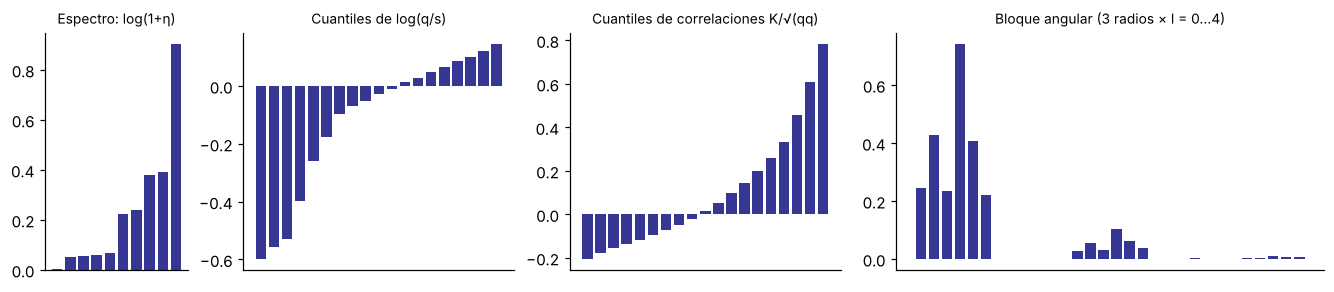

In [14]:
toro = nubes[fams.index("torus")]
cdu = CDDescriptor()
f = cdu(toro)
verifica(f.shape == (78,), "el descriptor CD_U mide 78 en 3D")
r2 = np.random.default_rng(7)
Y = random_similarity(toro, r2, reflect=True)[r2.permutation(len(toro))]
Y[:, 0] *= -1                                   # reflexión explícita
dif = np.max(np.abs(cdu(Y) - f))
verifica(dif < 1e-9, f"invariante a rotación, reflexión, escala, traslación y permutación (dif. máx. {dif:.1e})")
verifica(np.max(np.abs(moment_descriptor(Y) - moment_descriptor(toro))) < 1e-9, "el control M_U también es invariante")

fig, ax = plt.subplots(1, 4, figsize=(15, 2.8), gridspec_kw={"width_ratios": [10, 19, 19, 30]})
titulos = {"logspec": "Espectro: log(1+η)", "scores": "Cuantiles de log(q/s)", "corr": "Cuantiles de correlaciones K/√(qq)", "angular": "Bloque angular (3 radios × l = 0…4)"}
for a, (k, b) in zip(ax, cdu.blocks_.items()):
    a.bar(range(len(b)), b, color=AZUL); a.set_title(titulos[k], fontsize=9); a.set_xticks([])
guardar(fig, "descriptor_bloques_toro", "4.5 Descriptor invariante")
plt.show()

> **Para la tesis → 4.5 Descriptor invariante de objetos**
>
> *Figura:* `09_descriptor_bloques_toro.png` — «Los cuatro bloques del descriptor CD_U para un toro.» Acompañar con el diagrama de flujo de la presentación.
>
> *Texto modelo:* El descriptor CD_U concatena cuatro bloques calculados sobre la nube normalizada con la base ponderada de grado 2: el espectro de la matriz de momentos (10 valores en 3D), 19 cuantiles de log(q/s), 19 cuantiles de las correlaciones K(xᵢ,xⱼ)/√(qᵢqⱼ) y 30 invariantes radial-angulares. Es invariante a traslación, escala, rotación, reflexión y permutación de los puntos; numéricamente, el cambio máximo bajo estas transformaciones es menor a 10⁻⁹.

## E3. Recuperación de objetos sintéticos

Lee `objetos_3d.csv` y `objetos_2d.csv` (generados por `benchmarks/objetos_invariantes.py`). Con `RECALCULAR_OBJETOS = True` se vuelven a generar (unos minutos).

**mAP, familias 3D**

condition,Limpio,Ruido,Densidad,Oclusión,Atípicos
method,,,,,
CD_U,0.912,0.903,0.468,0.643,0.667
CD_U_metric,0.940,0.932,0.917,0.896,0.733
CD_W,0.916,0.905,0.520,0.682,0.377
CD_W_metric,0.937,0.926,0.940,0.914,0.377
D2,0.759,0.759,0.602,0.652,0.702
M_U,0.840,0.840,0.411,0.502,0.527
M_U_metric,0.885,0.885,0.869,0.726,0.551


✔ sintéticos 3D: CD_U + métrica supera a M_U + métrica en las cinco condiciones


Figura guardada: notebooks/figuras_tesis/10_objetos_3d_map.png  →  5.4 Objetos sintéticos


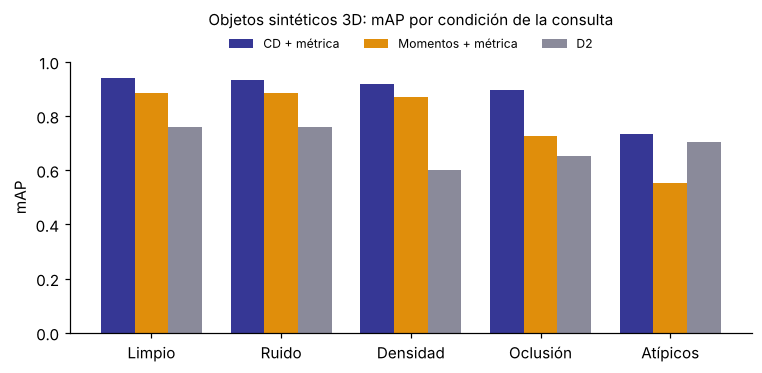

In [15]:
if RECALCULAR_OBJETOS:
    import subprocess
    for d in (2, 3):
        subprocess.run([sys.executable, str(RAIZ / "benchmarks/objetos_invariantes.py"), "--dim", str(d)], check=True, cwd=RAIZ)
COND = ["clean", "noise", "density", "occlusion", "outliers"]
NOMBRE_C = {"clean": "Limpio", "noise": "Ruido", "density": "Densidad", "occlusion": "Oclusión", "outliers": "Atípicos"}

def tablas_objetos(archivo):
    d = pd.read_csv(archivo)
    m = d[~d.method.str.contains(" - ")].pivot_table(index="method", columns="condition", values="mAP").reindex(columns=COND)
    c = d[d.method.str.contains(" - ")].set_index(["method", "condition"])[["mAP", "ci_low", "ci_high"]]
    return m, c

m3, c3 = tablas_objetos(RES / "objetos_3d.csv")
display(Markdown("**mAP, familias 3D**")); display(m3.rename(columns=NOMBRE_C).round(3))
k = "CD_U_metric - M_U_metric"
verifica(all(c3.loc[(k, cc), "ci_low"] > 0 for cc in COND), "sintéticos 3D: CD_U + métrica supera a M_U + métrica en las cinco condiciones")

def grafica_mAP(m, titulo, metodos=("CD_U_metric", "M_U_metric", "D2"), etiquetas=("CD + métrica", "Momentos + métrica", "D2")):
    fig, ax = plt.subplots(figsize=(8, 3.2)); w = 0.26
    for i, (mm, lab, col) in enumerate(zip(metodos, etiquetas, (AZUL, NARANJA, GRIS))):
        ax.bar(np.arange(len(COND)) + (i - 1) * w, m.loc[mm, COND], w, label=lab, color=col)
    ax.set_xticks(range(len(COND))); ax.set_xticklabels([NOMBRE_C[c] for c in COND]); ax.set_ylabel("mAP"); ax.set_ylim(0, 1)
    ax.set_title(titulo, fontsize=10, pad=24); ax.legend(frameon=False, ncol=3, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    return fig

fig = grafica_mAP(m3, "Objetos sintéticos 3D: mAP por condición de la consulta")
guardar(fig, "objetos_3d_map", "5.4 Objetos sintéticos")
plt.show()

> **Para la tesis → 5.4 Descripción de objetos sintéticos**
>
> *Figura:* `10_objetos_3d_map.png`.
>
> *Texto modelo:* En las familias sintéticas, CD_U con métrica multivista supera al control de momentos en las cinco condiciones (en limpio, +0.055 de mAP con IC 95 % [+0.038, +0.073]). Estas familias son pocas y muy distintas entre sí, por lo que sirven para verificar la implementación y las invariancias, no para afirmar superioridad.

---
# Parte F · ModelNet10 (cap. 5.5)

Lee `modelnet10_test.csv` y `modelnet10_dev.csv` de la corrida final (`python benchmarks/modelnet10.py --root … --split test|dev`). Si defines `MODELNET_ROOT`, la celda los vuelve a generar (unos minutos).

**Qué verificar:** que lo que dice el texto de la tesis es cierto en los datos: empate (IC con 0) en limpio, ruido y densidad; IC positivo con oclusión y atípicos en **ambos** conjuntos.

**Prueba, consultas limpias**

,nn,mAP
method,,
CD_U,0.695,0.383
CD_W,0.660,0.365
M_U,0.720,0.399
D2,0.440,0.272
CD_U_metric,0.725,0.400
M_U_metric,0.760,0.406


**mAP por condición (prueba)**

condition,Limpio,Ruido,Densidad,Oclusión,Atípicos
method,,,,,
CD_U,0.383,0.383,0.350,0.336,0.253
CD_U_metric,0.400,0.397,0.371,0.333,0.281
CD_W,0.365,0.365,0.330,0.327,0.173
D2,0.272,0.272,0.261,0.243,0.258
M_U,0.399,0.398,0.368,0.322,0.233
M_U_metric,0.406,0.405,0.372,0.309,0.224


✔ prueba · Limpio: empate (IC incluye 0)
✔ prueba · Ruido: empate (IC incluye 0)
✔ prueba · Densidad: empate (IC incluye 0)
✔ Oclusión: CD gana en prueba y en desarrollo
✔ Atípicos: CD gana en prueba y en desarrollo


Figura guardada: notebooks/figuras_tesis/11_modelnet10_contrastes.png  →  5.5 ModelNet10 (figura principal)


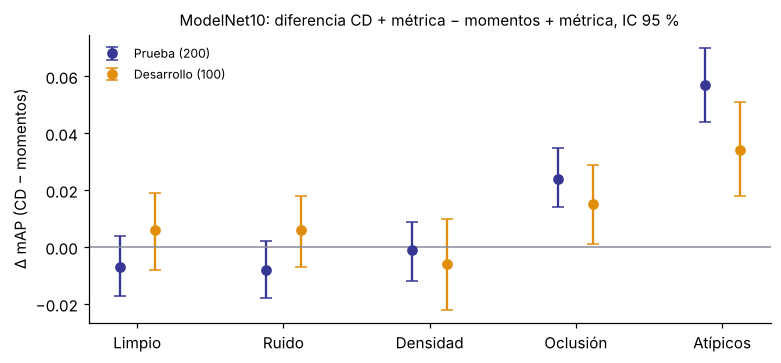

In [16]:
if MODELNET_ROOT is not None:
    import subprocess
    for sp in ("test", "dev"):
        subprocess.run([sys.executable, str(RAIZ / "benchmarks/modelnet10.py"), "--root", str(MODELNET_ROOT), "--split", sp], check=True, cwd=RAIZ)

archivos = {sp: RES / f"modelnet10_{sp}.csv" for sp in ("test", "dev")}
if not all(a.exists() for a in archivos.values()):
    print("Faltan los CSV de ModelNet10: corre benchmarks/modelnet10.py o define MODELNET_ROOT.")
else:
    mt, ct = tablas_objetos(archivos["test"]); md_, cd_ = tablas_objetos(archivos["dev"])
    nn = pd.read_csv(archivos["test"]).query("condition == 'clean' and not method.str.contains(' - ')", engine="python").set_index("method")[["nn", "mAP"]]
    display(Markdown("**Prueba, consultas limpias**")); display(nn.round(3))
    display(Markdown("**mAP por condición (prueba)**")); display(mt.rename(columns=NOMBRE_C).round(3))
    k = "CD_U_metric - M_U_metric"
    for cc in ("clean", "noise", "density"):
        verifica(ct.loc[(k, cc), "ci_low"] < 0 < ct.loc[(k, cc), "ci_high"], f"prueba · {NOMBRE_C[cc]}: empate (IC incluye 0)")
    for cc in ("occlusion", "outliers"):
        verifica(ct.loc[(k, cc), "ci_low"] > 0 and cd_.loc[(k, cc), "ci_low"] > 0, f"{NOMBRE_C[cc]}: CD gana en prueba y en desarrollo")

    fig, ax = plt.subplots(figsize=(8, 3.4))
    for desp, (c, lab, col) in zip((-0.12, 0.12), ((ct, "Prueba (200)", AZUL), (cd_, "Desarrollo (100)", NARANJA))):
        y = c.loc[k].reindex(COND)
        ax.errorbar(np.arange(len(COND)) + desp, y.mAP, yerr=[y.mAP - y.ci_low, y.ci_high - y.mAP], fmt="o", color=col, capsize=4, label=lab)
    ax.axhline(0, color=GRIS, lw=1)
    ax.set_xticks(range(len(COND))); ax.set_xticklabels([NOMBRE_C[c] for c in COND])
    ax.set_ylabel("Δ mAP (CD − momentos)"); ax.legend(frameon=False, fontsize=8)
    ax.set_title("ModelNet10: diferencia CD + métrica − momentos + métrica, IC 95 %", fontsize=10)
    guardar(fig, "modelnet10_contrastes", "5.5 ModelNet10 (figura principal)")
    plt.show()

> **Para la tesis → 5.5 ModelNet10 y 5.7 (H3)**
>
> *Figura:* `11_modelnet10_contrastes.png` — «Diferencia de mAP entre CD + métrica y momentos + métrica por condición de la consulta, con IC 95 % por bootstrap pareado estratificado. Azul: 200 consultas de prueba; naranja: 100 de desarrollo.»
>
> *Texto modelo:* En datos limpios, con ruido y con sesgo de densidad, el descriptor CD empata con el control de momentos: el intervalo de la diferencia incluye cero en los dos conjuntos de consultas. Con oclusión de 20 % y con 5 % de valores atípicos, CD lo supera (+0.024 y +0.057 de mAP en prueba), con intervalo positivo también en desarrollo. Por tanto, H3 se rechaza en general y se confirma para nubes incompletas o contaminadas.
>
> *Notas:* Esta es la figura que faltaba en §11.5 del doc de capítulos. Si vuelves a correr ModelNet10, las cifras del texto deben salir de la tabla de arriba.

---
# Parte G · Resumen de verificaciones y figuras

In [17]:
ok = sum(v for v, _ in VERIF)
print(f"Verificaciones: {ok} de {len(VERIF)} correctas")
verifica(ok == len(VERIF), "todas las verificaciones pasaron")
display(pd.DataFrame(FIGS, columns=["archivo", "sección de la tesis"]))

Verificaciones: 41 de 41 correctas
✔ todas las verificaciones pasaron


,archivo,sección de la tesis
0,01_ejemplo_1d.png,2.5.1 Definición (ejemplo)
1,02_circulo_pinv_vs_ridge.png,2.5.4 Singularidad y regularización
2,03_soporte_grado.png,5.1 Estimación de soporte y efecto del grado
3,04_escenarios_2d.png,3.3 Datos (escenarios 2D)
4,05_perturbaciones_2d.png,3.3 Datos (perturbaciones)
5,06_agrupamiento_2d_semilla100.png,5.2 Agrupamiento 2D (figura principal)
6,07_embeddings_entrelazado.png,5.3 Embeddings
7,08_familias_3d.png,3.3 Datos (objetos sintéticos)
8,09_descriptor_bloques_toro.png,4.5 Descriptor invariante
9,10_objetos_3d_map.png,5.4 Objetos sintéticos


### Cómo pasar esto a la tesis

1. **Figuras:** inserta los PNG de `notebooks/figuras_tesis/` en la sección indicada. Pie de figura = una frase de qué muestra + datos usados (semilla, N).
2. **Tablas:** copia las que muestra el cuaderno o, mejor, las de `benchmarks/results/tablas_tesis.md` (mismas cifras, ya en Markdown).
3. **Texto:** los bloques *Para la tesis →* son modelos; ajústalos al tono del documento, pero no cambies las cifras sin volver a correr la celda.
4. **Antes de entregar:** *Restart & Run All*; la última celda debe decir que todas las verificaciones pasaron.